# Chapitre 3. Variables aléatoires : F, densité, survie, quantile

Le chapitre pont vers la VaR : lire un quantile sur la courbe de F, en continu, en discret et pour une perte mixte.

*Cours « Probabilités pour la gestion des risques », M1 GRAF. Exécutez les cellules dans l'ordre (Maj + Entrée).*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate
from math import comb, perm, factorial, log, exp

rng = np.random.default_rng(42)   # graine : memes resultats a chaque execution

## Exemple résolu : Coût d'un sinistre (exponentielle de moyenne 500)

In [2]:
X = stats.expon(scale=500)
print('(a) F(1000)              =', X.cdf(1000))
print('(b) S(1000)              =', X.sf(1000))
print('(c) P(500 < X <= 1500)   =', X.cdf(1500) - X.cdf(500))
print('(d) mediane              =', X.median())
print('(e) quantile 99 %        =', X.ppf(0.99))

sim = X.rvs(size=1_000_000, random_state=rng)
print('Simulation : S(1000) ~', np.mean(sim > 1000), '| q99 ~', np.quantile(sim, 0.99))

(a) F(1000)              = 0.8646647167633873
(b) S(1000)              = 0.1353352832366127
(c) P(500 < X <= 1500)   = 0.3180923728035784
(d) mediane              = 346.5735902799726
(e) quantile 99 %        = 2302.5850929940457
Simulation : S(1000) ~ 0.135444 | q99 ~ 2297.0382160830945


## Lecture graphique du quantile
On part de α sur l'axe vertical, on rejoint la courbe de F, on descend sur l'axe des x.

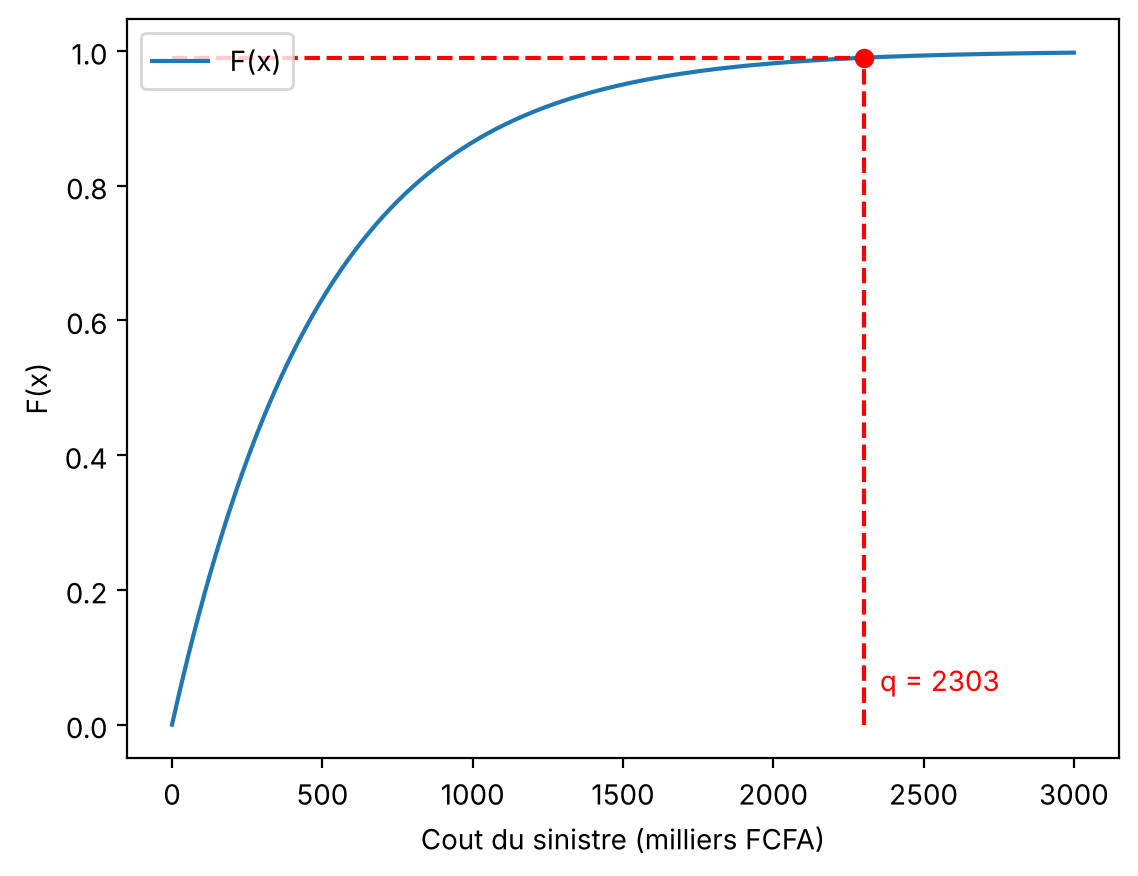

In [3]:
alpha = 0.99
xs = np.linspace(0, 3000, 500)
q = X.ppf(alpha)
plt.plot(xs, X.cdf(xs), label='F(x)')
plt.hlines(alpha, 0, q, colors='red', linestyles='--')
plt.vlines(q, 0, alpha, colors='red', linestyles='--')
plt.scatter([q], [alpha], color='red', zorder=3)
plt.text(q, 0.05, f'  q = {q:.0f}', color='red')
plt.xlabel('Cout du sinistre (milliers FCFA)'); plt.ylabel('F(x)'); plt.legend(); plt.show()

## Loi discrète : F en escalier et inverse généralisé

F : [0.6  0.85 0.95 1.  ]
Quantiles 0.50, 0.85, 0.90, 0.99 : [0. 1. 2. 3.]
0.5 -> 0
0.85 -> 1
0.9 -> 2
0.99 -> 3


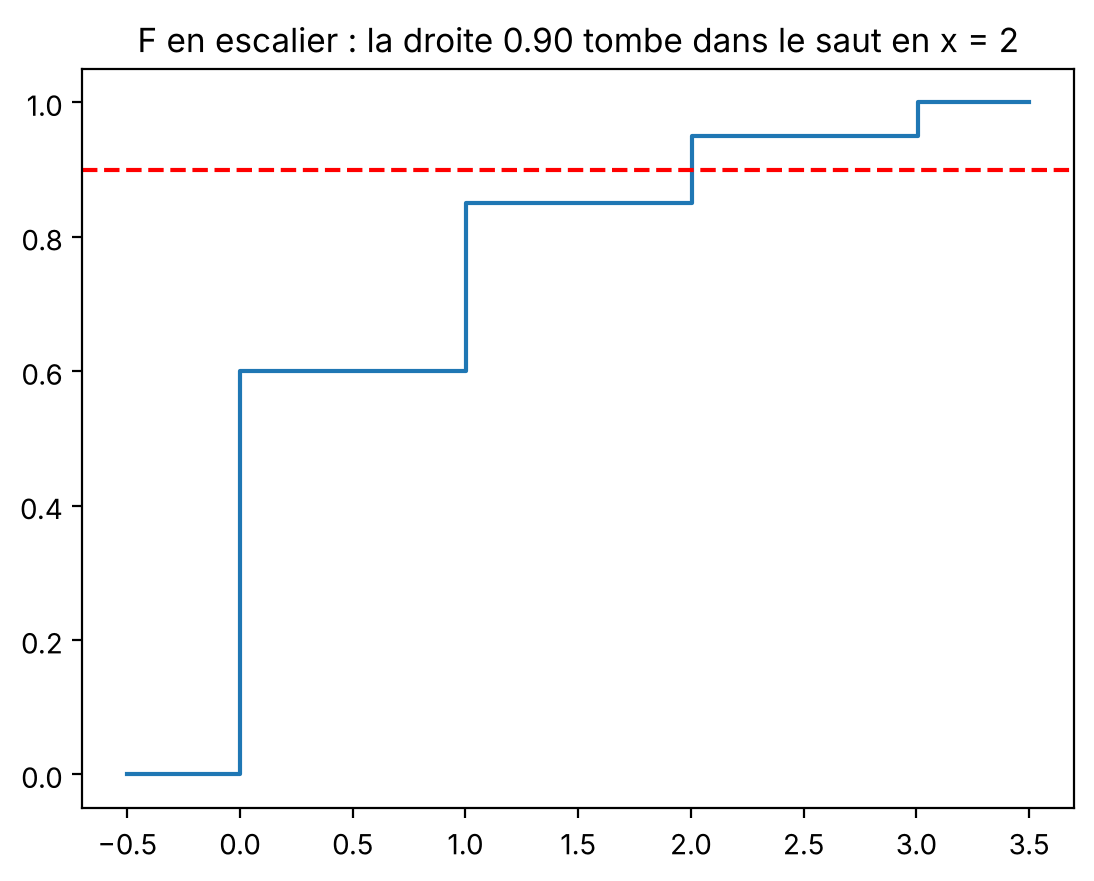

In [4]:
valeurs, probas = [0, 1, 2, 3], [0.60, 0.25, 0.10, 0.05]
N = stats.rv_discrete(values=(valeurs, probas))
print('F :', N.cdf(valeurs))
print('Quantiles 0.50, 0.85, 0.90, 0.99 :', N.ppf([0.50, 0.85, 0.90, 0.99]))

def quantile_discret(valeurs, probas, alpha):
    # plus petite valeur x telle que F(x) >= alpha
    F = np.cumsum(probas)
    return valeurs[np.argmax(F >= alpha - 1e-12)]

for a in [0.50, 0.85, 0.90, 0.99]:
    print(a, '->', quantile_discret(valeurs, probas, a))

xs = np.linspace(-0.5, 3.5, 400)
plt.step(xs, N.cdf(xs), where='post'); plt.axhline(0.90, ls='--', color='red')
plt.title('F en escalier : la droite 0.90 tombe dans le saut en x = 2'); plt.show()

## [N3] Perte mixte : P(X = 0) = 0,9, sinon exponentielle de moyenne 1000

In [5]:
def F_mixte(x):
    x = np.asarray(x, dtype=float)
    return np.where(x < 0, 0, 0.9 + 0.1 * (1 - np.exp(-x / 1000)))

print('q 0.85 = 0 car F(0) =', F_mixte(0))
print('q 0.95 exact =', 1000 * np.log(2))

n = 1_000_000
perte = np.where(rng.random(n) < 0.9, 0, rng.exponential(1000, size=n))
print('Simulation : q 0.85 ~', np.quantile(perte, 0.85), '| q 0.95 ~', np.quantile(perte, 0.95))

q 0.85 = 0 car F(0) = 0.9
q 0.95 exact = 693.1471805599452
Simulation : q 0.85 ~ 0.0 | q 0.95 ~ 687.9858435008637


## [N3] Méthode d'inversion : simuler une exponentielle à partir d'une uniforme

In [6]:
U = rng.random(1_000_000)
X_inv = -np.log(1 - U) / (1/500)
print('Moyenne ~', X_inv.mean(), '| q99 ~', np.quantile(X_inv, 0.99), '(exact', X.ppf(0.99), ')')

Moyenne ~ 499.8543818988771 | q99 ~ 2305.290099211996 (exact 2302.5850929940457 )


## Vérification des exercices 3.1 à 3.5

In [7]:
N31 = stats.rv_discrete(values=([0, 1, 2, 3], [0.50, 0.30, 0.15, 0.05]))
print('3.1 : F =', N31.cdf([0, 1, 2, 3]), '| P(N>=2) =', round(N31.sf(1), 4),
      '| quantiles =', N31.ppf([0.5, 0.9, 0.95, 0.99]))

import sympy as sp
x, c = sp.symbols('x c', positive=True)
c_val = sp.solve(sp.integrate(c * x**2, (x, 0, 2)) - 1, c)[0]
F32 = sp.integrate(c_val * x**2, (x, 0, x))
print('3.2 : c =', c_val, '| F =', F32, '| P(X>1) =', 1 - F32.subs(x, 1), '| mediane =', sp.N(sp.solve(F32 - sp.Rational(1, 2), x)[0]))

theta = 1000 / np.log(5)
print('3.3 : theta =', theta, '| q99 =', stats.expon(scale=theta).ppf(0.99))

s, t, lam_ = 2000, 1500, 1/800
Xe = stats.expon(scale=1/lam_)
print('3.4 : P(X>s+t | X>s) =', Xe.sf(s + t) / Xe.sf(s), '= P(X>t) =', Xe.sf(t))

perte = np.where(rng.random(n) < 0.8, 0, rng.uniform(0, 10_000, size=n))
print('3.5 : P(X>5000) ~', np.mean(perte > 5000), '| q50, q90, q99 ~', np.quantile(perte, [0.5, 0.9, 0.99]))

3.1 : F = [0.5  0.8  0.95 1.  ] | P(N>=2) = 0.2 | quantiles = [0. 2. 2. 3.]


3.2 : c = 3/8 | F = x**3/8 | P(X>1) = 7/8 | mediane = 1.58740105196820
3.3 : theta = 621.3349345596118 | q99 = 2861.353116146786
3.4 : P(X>s+t | X>s) = 0.15335496684492844 = P(X>t) = 0.15335496684492847
3.5 : P(X>5000) ~ 0.10053 | q50, q90, q99 ~ [   0.         5027.23836669 9508.80716506]
